In [1]:
import numpy as np
import seaborn as sns # optional
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import matplotlib.image as mpimg
import pathlib
from matplotlib.colors import rgb_to_hsv
import pandas as pd

In [2]:
#for full path
here = pathlib.Path.cwd()

In [3]:
#get sentinel files 
files_2017 = sorted((here / 'sentinel-data' / 'S2_2017-07-12').rglob('*.tiff'))
files_2018 = sorted((here / 'sentinel-data' / 'S2_2018-07-12').rglob('*.tiff'))
files_2019 = sorted((here / 'sentinel-data' / 'S2_2019-07-12').rglob('*.tiff'))

In [4]:
for fl in (files_2017, files_2018, files_2019):
    print(len(fl), fl[3].name, fl[7].name, fl[17].name)

22 Sentinel-2_L2A_B04_Raw.tiff Sentinel-2_L2A_B08_Raw.tiff Sentinel-2_L2A_NDVI.tiff
22 Sentinel-2_L2A_B04_Raw.tiff Sentinel-2_L2A_B08_Raw.tiff Sentinel-2_L2A_NDVI.tiff
22 Sentinel-2_L2A_B04_Raw.tiff Sentinel-2_L2A_B08_Raw.tiff Sentinel-2_L2A_NDVI.tiff


In [5]:
#get white light files
files_white = sorted((here / 'sentinel-data' / 'White_light').rglob('*.jpg'))

In [6]:
for i, file in enumerate(files_white):
    print(f"\t{i}\t{file}")

	0	C:\Users\AnaAm\ccd_data\sentinel-data\White_light\2014Feb.jpg
	1	C:\Users\AnaAm\ccd_data\sentinel-data\White_light\2016May.jpg
	2	C:\Users\AnaAm\ccd_data\sentinel-data\White_light\2020Nov.jpg
	3	C:\Users\AnaAm\ccd_data\sentinel-data\White_light\2021Dec.jpg
	4	C:\Users\AnaAm\ccd_data\sentinel-data\White_light\2022Jan.jpg
	5	C:\Users\AnaAm\ccd_data\sentinel-data\White_light\2023Oct.jpg




Where $R$ is the reflectance in some band $A$ or $B$. You can see some of the (many) band combinations [on this site](https://gisgeography.com/sentinel-2-bands-combinations/), or if you're feeling adventurous you can explore the [Awesome Spectral Indices](https://awesome-spectral-indices.github.io/awesome-spectral-indices/) page (see also [the paper about it](https://www.nature.com/articles/s41597-023-02096-0)). A few combinations are listed below:

* Natural Color: B4, B3, B2 (665nm, 560nm, 490nm respectively)
* Infrared: B8, B4, B3 (842nm, 665nm, 560nm)
* Short-Wave infrared: B12, B8A, B4 (2190nm, 865nm, 665nm)
* Agriculture: B11, B8, B2 (1610nm, 842nm, 490nm)
* Vegetation Index: (B8 - B4) / (B8 + B4)
* Red Edge Vegetation Index: (B3 - B4) / (B3 + B4) + (B6 - B4) / (B6 + B4)
* Moisture Index: (B8A - B11) / (B8A + B11)
* Normalized Water Index: (B3 - B8) / (B3 + B8)
* Ferrous Silicates: B12 / B11


In [36]:
# you will use the Google Earth images to make a plot of the land area as a function of time
#and the Sentinel-2 images to make a plot of the land area covered in vegetation as a function of time. 

In [7]:
def make_ndi(band1, band2, band3=None):
    """
    take two bands and make a normalized difference image
    """
    band1[band1 <= 0] = np.nan
    band2[band2 <= 0] = np.nan
    ndi = (band1 - band2) / (band1 + band2)

    if band3 is not None:
        band3[band3 <= 0] = np.nan 
        ndi += (band3 - band2) / (band3 + band2)
    return ndi

In [8]:
b8 = rasterio.open(files_2017[7]).read(1)
b4 = rasterio.open(files_2017[3]).read(1)
veggie_2017 = make_ndi(b8, b4)

In [9]:
b8 = rasterio.open(files_2018[7]).read(1)
b4 = rasterio.open(files_2018[3]).read(1)
veggie_2018 = make_ndi(b8, b4)

In [10]:
b8 = rasterio.open(files_2019[7]).read(1)
b4 = rasterio.open(files_2019[3]).read(1)
veggie_2019 = make_ndi(b8, b4)

In [11]:
with rasterio.open(files_2017[7]) as src:
    resolution = src.res  # resolution in degress(x, y)
    bounds = src.bounds   # limits (left, bottom, right, top)

#calculate the latitude centre to adjust the longitude conversion
lat_center = (bounds.bottom + bounds.top) / 2
meters_per_degree_lat = 111320
meters_per_degree_lon = 111320 * np.cos(np.radians(lat_center))

# pixels size in meters for X and Y 
pixel_width_m = abs(resolution[0]) * meters_per_degree_lon
pixel_height_m = abs(resolution[1]) * meters_per_degree_lat

#Pixels area 
pixel_area_m2 = pixel_width_m * pixel_height_m
print(f"Pixels area: {pixel_area_m2:.2f} m^2")

Pixels area: 87.75 m^2


In [12]:
#Total vegetation area for every year
veg_area_2017 = np.sum(veggie_2017 > 0.45) * pixel_area_m2
veg_area_2018 = np.sum(veggie_2018 > 0.45) * pixel_area_m2
veg_area_2019 = np.sum(veggie_2019 > 0.45) * pixel_area_m2
#store the data
sent_years = [2017, 2018, 2019]
veg_areas = [veg_area_2017, veg_area_2018, veg_area_2019]

In [13]:
land_areas = []
google_years = [2014, 2016, 2020, 2021, 2022, 2023] 

for img_path in files_white:
    img = mpimg.imread(img_path)
    img_norm = img / 255
    hsv_img = rgb_to_hsv(img_norm)

    #Apply land mask 
    water_mask = hsv_img[:, :, 0] > 0.45 # lo que se tapa (agua)
    land_mask = ~water_mask # lo que queda (tierra)
    num_pixels = np.sum(land_mask)

    #visualasing the land
    #fig, ax = plt.subplots(figsize=(5,4))
    #ax.imshow(np.ma.masked_array(img[..., 0], mask=water_mask))
    #ax.set_title(img_path.stem)
    #plt.show()

    long_bar = 312
    scale = 600 / (long_bar)
    factor = scale**2 

    land_area = num_pixels * factor
    land_areas.append(land_area)

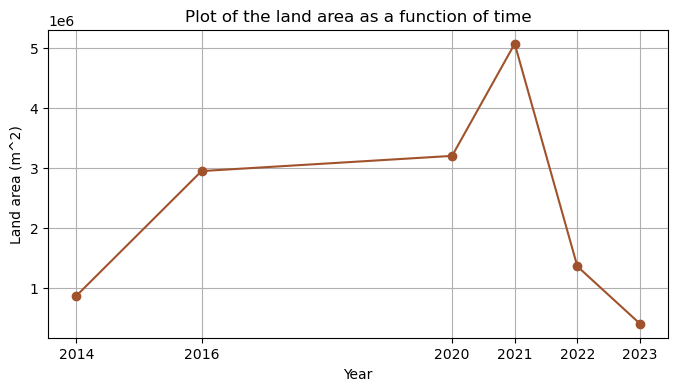

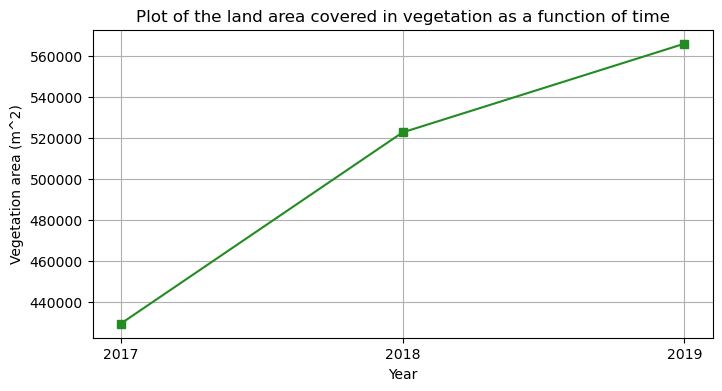

In [14]:
#1st graphic 
plt.figure(figsize=(8, 4))
plt.plot(google_years, land_areas, marker='o', color='sienna')
plt.xticks(google_years)
plt.title('Plot of the land area as a function of time')
plt.xlabel('Year')
plt.ylabel('Land area (m^2)')
plt.grid(True)
plt.show()

#2nd Graphic
plt.figure(figsize=(8, 4))
plt.plot(sent_years, veg_areas, marker='s', color='forestgreen')
plt.xticks(sent_years) 
plt.title('Plot of the land area covered in vegetation as a function of time')
plt.xlabel('Year')
plt.ylabel('Vegetation area (m^2)')
plt.grid(True)
plt.show()

## Visualising the data


First, we plot the Google Earth images. Then we plot only the veggie for the files we have processed, so we can plot the vegetation on top of the Google Earth images and have a real sense on land covered on veggie. 
Lastly, we can visualise the NVDI image for the vegetation and compare it with what we did. 

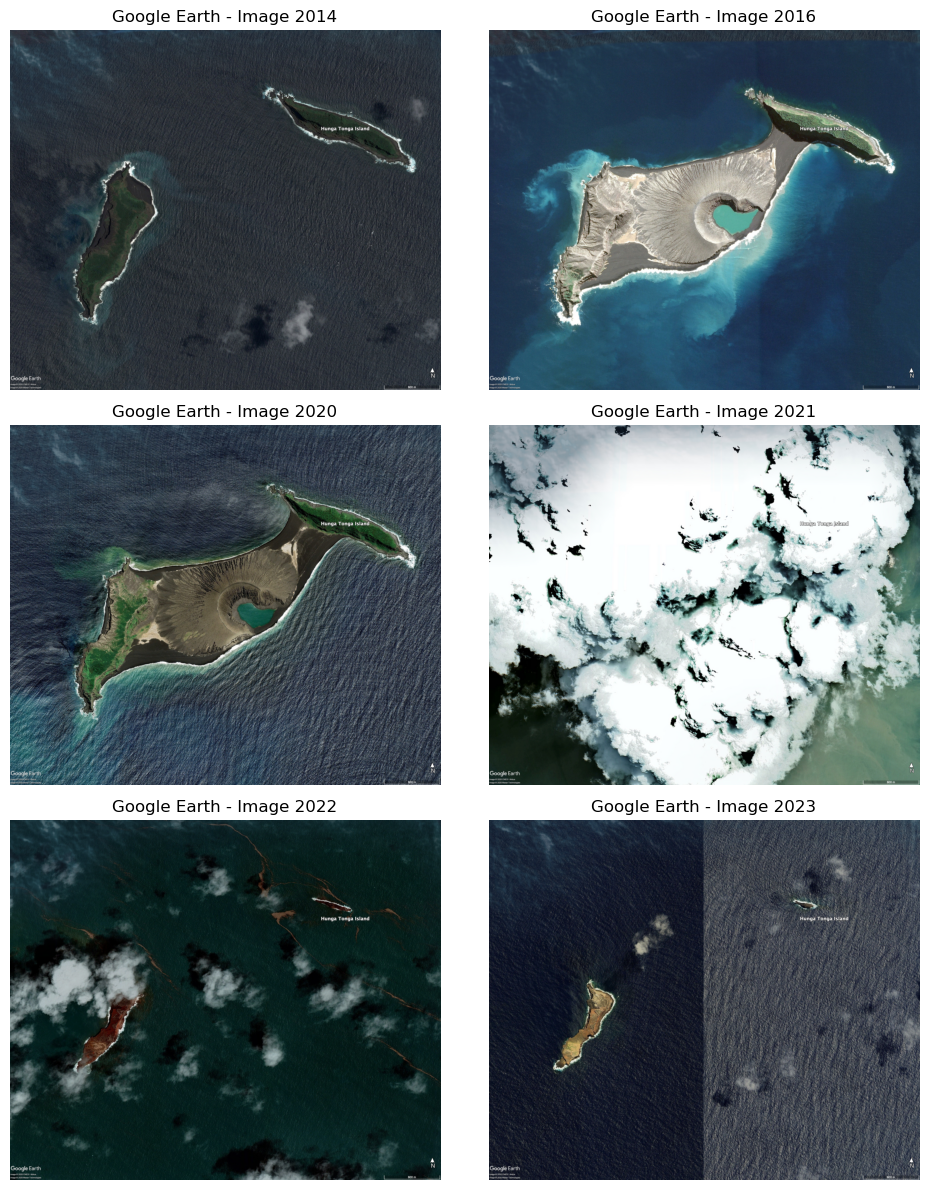

In [45]:
plt.close('all')
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 12), tight_layout=True)
axes = axes.ravel()

for i, ax in enumerate(axes):
    if i < len(files_white):
        img = mpimg.imread(files_white[i])
        img_norm = img / 255
        hsv_img = rgb_to_hsv(img_norm)
    
        ax.imshow(img) 
        ax.set_title(f"Google Earth - Image {google_years[i]}")
        ax.axis('off')

plt.show()

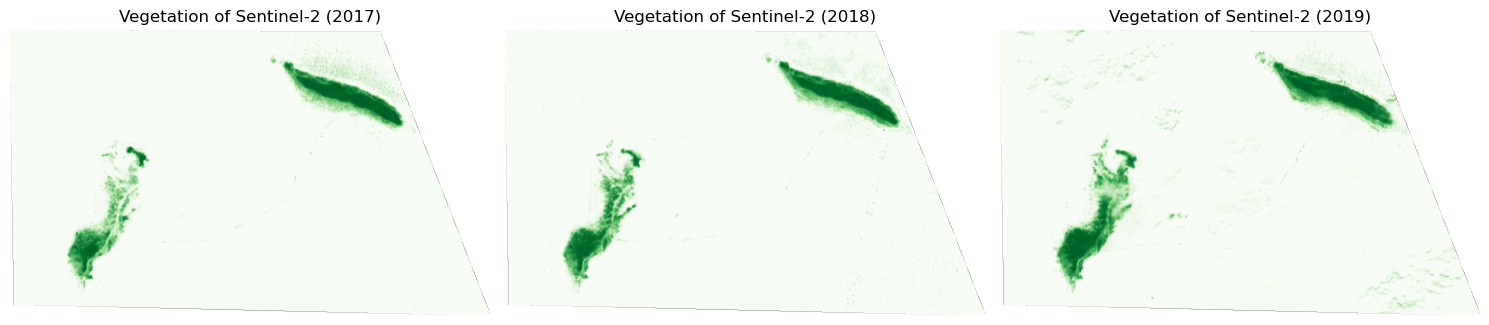

In [15]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), tight_layout=True)
sent_vegetation = [veggie_2017, veggie_2018, veggie_2019]
for i, ax in enumerate(axes):
    im = ax.imshow(sent_vegetation[i], cmap='Greens', vmin=0, vmax=1)
    
    ax.set_title(f"Vegetation of Sentinel-2 ({sent_years[i]})")
    ax.axis('off') 
plt.show()

In [18]:
def get_rgb_image(file_list):
    
    r_path = [f for f in file_list if 'B04' in str(f)][0]
    g_path = [f for f in file_list if 'B03' in str(f)][0]
    b_path = [f for f in file_list if 'B02' in str(f)][0]
    
    with rasterio.open(r_path) as src:
        r = src.read(1).astype(np.float32)
    with rasterio.open(g_path) as src:
        g = src.read(1).astype(np.float32)
    with rasterio.open(b_path) as src:
        b = src.read(1).astype(np.float32)
    
    rgb = np.dstack((r, g, b))
    return rgb
    
def gamma_corr(band):
    gamma = 2.0
    return np.power(band, 1 / gamma)

def brighten(band):
    alpha = 1.2
    beta = 0.0
    return np.clip((alpha * band + beta), 0, 1.0)

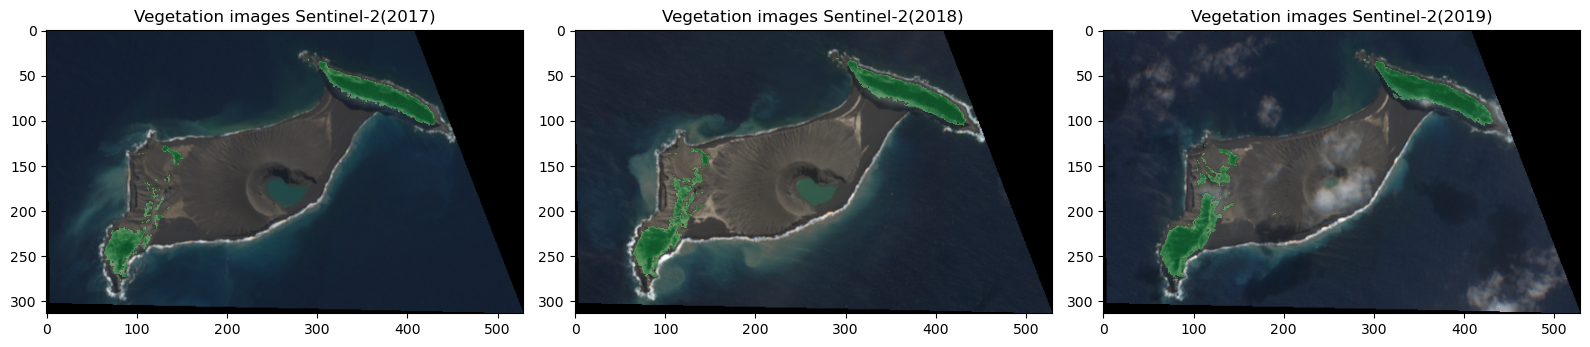

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 6), tight_layout=True)

sent_vegetation = [veggie_2017, veggie_2018, veggie_2019]
sent_files = [files_2017, files_2018, files_2019]
sent_years = [2017, 2018, 2019]


for i, ax in enumerate(axes):
    
    rgb_raw = get_rgb_image(sent_files[i])
    rgb_gcorr = gamma_corr(rgb_raw)
    rgb_final = brighten(rgb_gcorr)
  
    ax.imshow(rgb_final)
    
    # Creamos una máscara donde solo queden los valores de vegetación altos (ej. > 0.45)
    # y volvemos transparentes los demás valores usando np.ma.masked_where
    veg_mask = sent_vegetation[i] > 0.45
    masked_veg = np.ma.masked_where(~veg_mask, sent_vegetation[i])
    
    ax.imshow(masked_veg, cmap='Greens', alpha=0.6, vmin=0, vmax=1)
    
    ax.set_title(f"Vegetation images Sentinel-2({sent_years[i]})")
    ax.axis('on') 
plt.show()


In [16]:
#we upload the processed files to compare them with what we got 
veg_comp_2017 = rasterio.open(files_2017[17]).read(1)
veg_comp_2018 = rasterio.open(files_2018[17]).read(1)
veg_comp_2019 = rasterio.open(files_2019[17]).read(1)

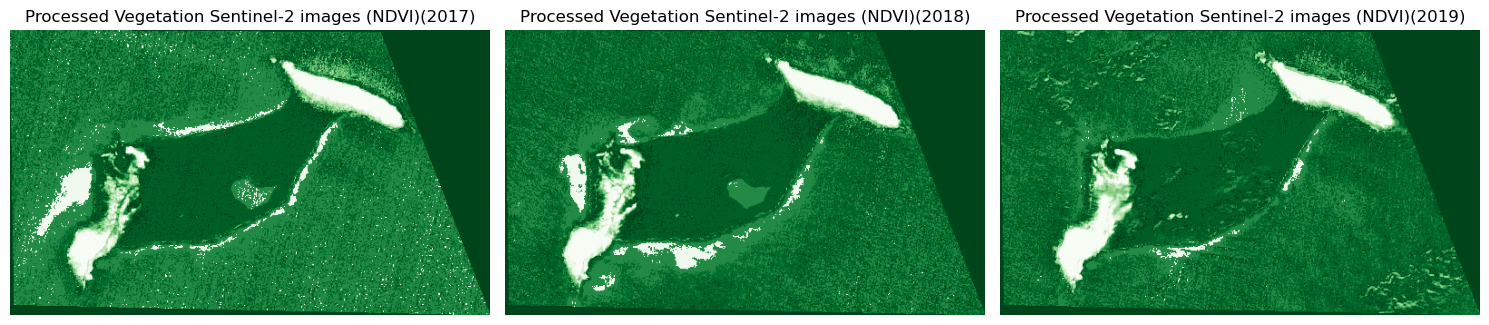

In [17]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), tight_layout=True)
sent_vegetation = [veg_comp_2017, veg_comp_2018, veg_comp_2019]
for i, ax in enumerate(axes):
    im = ax.imshow(sent_vegetation[i], cmap='Greens', vmin=0, vmax=1)
    
    ax.set_title(f"Processed Vegetation Sentinel-2 images (NDVI)({sent_years[i]})")
    ax.axis('off') 
plt.show()

## Quantitative Comparison between both data

In [20]:
years = [2017, 2018, 2019]
veggie_list = [veggie_2017, veggie_2018, veggie_2019]
veg_comp_list = [veg_comp_2017, veg_comp_2018, veg_comp_2019]

comp_results = []

for i, year in enumerate(years):
    v_raw = veggie_list[i]
    v_comp = veg_comp_list[i]
    #Manage possible NaN Values 
    valid_mask = ~np.isnan(v_raw) & ~np.isnan(v_comp)
    arr1 = v_raw[valid_mask]
    arr2 = v_comp[valid_mask]

    # Linear Correlation 
    correlacion = np.corrcoef(arr1, arr2)[0, 1]
    
    veggie_mean = np.mean(arr1)
    comp_mean = np.mean(arr2)
    
    comp_results.append({
        'year': year,
        'Media Veggie': round(media_veggie, 4),
        'Media Comp': round(media_comp, 4),
        'Correlation': round(correlacion, 4)
    })

df_comparacion = pd.DataFrame(comp_results)
print(df_comparacion)

   year  Media Veggie  Media Comp  Dif. Máxima  Correlation
0  2017       -0.1470      0.7670      1.42442      -0.2341
1  2018       -0.0792      0.8061      1.32235      -0.3644
2  2019       -0.0527      0.8150      1.40093      -0.6452


In [54]:
with rasterio.open(files_2018[17]) as src:
    print(src.indexes)
    print(src.dtypes)
    print(src.profile)

(1, 2, 3)
('float32', 'float32', 'float32')
{'driver': 'GTiff', 'dtype': 'float32', 'nodata': None, 'width': 529, 'height': 314, 'count': 3, 'crs': CRS.from_wkt('GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4326"]]'), 'transform': Affine(8.988657844990755e-05, 0.0, -175.413508,
       0.0, -8.412738853502405e-05, -20.530619), 'blockxsize': 529, 'blockysize': 8, 'tiled': False, 'compress': 'deflate', 'interleave': 'pixel'}


In [56]:
for y, veg, flist in zip([2017, 2018, 2019],
                         [veggie_2017, veggie_2018, veggie_2019],
                         [files_2017, files_2018, files_2019]):
    with rasterio.open(flist[17]) as src:
        for k in src.indexes:
            comp = src.read(k)
            m = ~np.isnan(veg) & ~np.isnan(comp)
            r = np.corrcoef(veg[m], comp[m])[0, 1]
            print(y, 'channel', k, 'r =', round(r, 3))

2017 channel 1 r = -0.234
2017 channel 2 r = -0.037
2017 channel 3 r = -0.338
2018 channel 1 r = -0.364
2018 channel 2 r = -0.191
2018 channel 3 r = -0.449
2019 channel 1 r = -0.645
2019 channel 2 r = -0.53
2019 channel 3 r = -0.707


The manually computed NDVI (B8, B4) was compared with the provided
`NDVI.tiff` product for 2017, 2018 and 2019. Inspecting the file shows that it
has three float32 bands (`src.indexes = (1, 2, 3)`), so it is a colour-rendered
image rather than a single-band array of NDVI values. Reading band 1 only gives
its red channel, with values between 0 and 1 and a mean of about 0.8, whereas
our NDVI keeps the full physical range (-1 to 1, mean between -0.15 and -0.05
because most of the scene is sea).

The pixel-by-pixel correlation between our NDVI and the three channels of the
product is negative or weak in all cases (from r = -0.04 to r = -0.71 depending
on the year and channel). This is expected for a colour map. Its channels are
not linear functions of the index, and the sea/land contrast appears inverted
in the provided image. Therefore the comparison is not a measure of how well
the two products agree, but a consequence of comparing different kinds of data.

Visually, however, both products identify the same vegetated areas in three years, and the vegetation patterns are consistent. Only
our NDVI is suitable for quantitative estimates such as the vegetated area.

For the land area from the Google Earth images, we used the hue channel of
the HSV image: pixels with hue > 0.45 (blue/cyan) are water and the rest are
land. The 2021 image is almost completely covered by clouds, which are not
blue, so its land area is overestimated and it should not be trusted.